In [ ]:
 print("Hello! My name is Divyanshi.")
 print("I am starting my AI/ML internship projects.")
 print("My first project is Student Performance Analysis.")

Hello! My name is Divyanshi.
I am starting my AI/ML internship projects.
My first project is Student Performance Analysis.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import pandas as pd
import numpy as np
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urllib.request.urlopen(url)
zip_data = io.BytesIO(response.read())

with zipfile.ZipFile(zip_data) as outer_zip:
    # Extract 'student.zip' which contains the actual CSV files
    with outer_zip.open('student.zip') as inner_zip_data:
        with zipfile.ZipFile(io.BytesIO(inner_zip_data.read())) as inner_zip:
            df = pd.read_csv(inner_zip.open("student-mat.csv"), sep=";")

print("Dataset downloaded and extracted successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded and extracted successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
import zipfile
import io

# Open and list the outer zip file contents
with zipfile.ZipFile(zip_data) as outer_zip:
    print("Outer ZIP file contents:")
    for file in outer_zip.namelist():
        print(f" - {file}")

    # Open and list the nested student.zip contents
    print("\nNested 'student.zip' contents:")
    with outer_zip.open('student.zip') as inner_zip_data:
        with zipfile.ZipFile(io.BytesIO(inner_zip_data.read())) as inner_zip:
            for file in inner_zip.namelist():
                print(f" - {file}")

Outer ZIP file contents:
 - .student.zip_old
 - student.zip

Nested 'student.zip' contents:
 - student-mat.csv
 - student-por.csv
 - student-merge.R
 - student.txt


In [ ]:
print("All columns in the dataset:")
for column in df.columns:
    print(column)

All columns in the dataset:
school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
G1
G2
G3


In [ ]:
print("Number of students:", len(df))
print("Number of features:", len(df.columns))

print("\nData types:")
print(df.dtypes)

Number of students: 395
Number of features: 33

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [ ]:
print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
0

Duplicate records:
0


In [ ]:
df = df.drop_duplicates()

df = df.dropna()

print("Data cleaning completed!")
print("Remaining records:", len(df))

Data cleaning completed!
Remaining records: 395


In [ ]:
features = [
    'studytime',
    'failures',
    'absences',
    'G1',
    'G2',
    'age'
]

X = df[features]
y = df['G3']

print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Input features:


,studytime,failures,absences,G1,G2,age
0,2,0,6,5,6,18
1,2,0,4,5,5,17
2,2,3,10,7,8,15
3,3,0,2,15,14,15
4,2,0,4,6,10,16



Target variable:


,G3
0,6
1,6
2,10
3,15
4,10


In [ ]:
print("MEAN")
display(df[features + ['G3']].mean())

print("MEDIAN")
display(df[features + ['G3']].median())

print("STANDARD DEVIATION")
display(df[features + ['G3']].std())

MEAN


,0
studytime,2.035443
failures,0.334177
absences,5.708861
G1,10.908861
G2,10.713924
age,16.696203
G3,10.415190


MEDIAN


,0
studytime,2.0
failures,0.0
absences,4.0
G1,11.0
G2,11.0
age,17.0
G3,11.0


STANDARD DEVIATION


,0
studytime,0.839240
failures,0.743651
absences,8.003096
G1,3.319195
G2,3.761505
age,1.276043
G3,4.581443


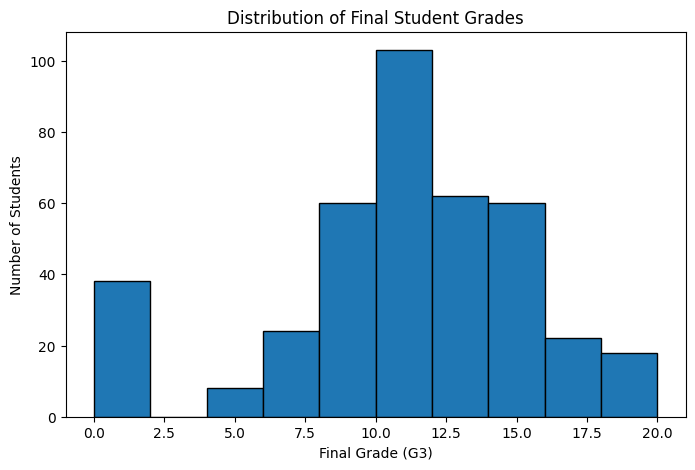

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df['G3'], bins=10, edgecolor='black')

plt.title('Distribution of Final Student Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')

plt.show()

In [ ]:
df.to_csv(
    '/content/cleaned_student_performance.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


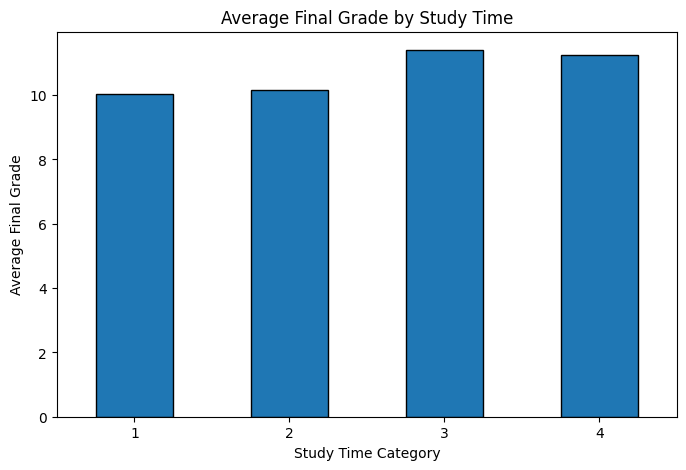

In [ ]:
plt.figure(figsize=(8,5))

study_performance = df.groupby('studytime')['G3'].mean()

study_performance.plot(kind='bar', edgecolor='black')

plt.title('Average Final Grade by Study Time')
plt.xlabel('Study Time Category')
plt.ylabel('Average Final Grade')
plt.xticks(rotation=0)

plt.show()

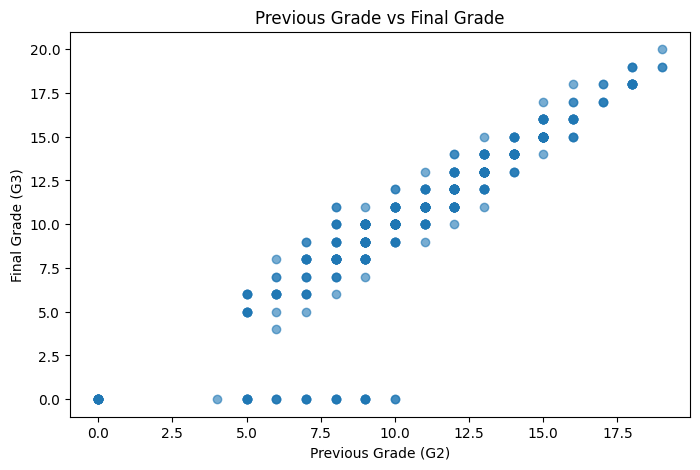

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df['G2'], df['G3'], alpha=0.6)

plt.title('Previous Grade vs Final Grade')
plt.xlabel('Previous Grade (G2)')
plt.ylabel('Final Grade (G3)')

plt.show()

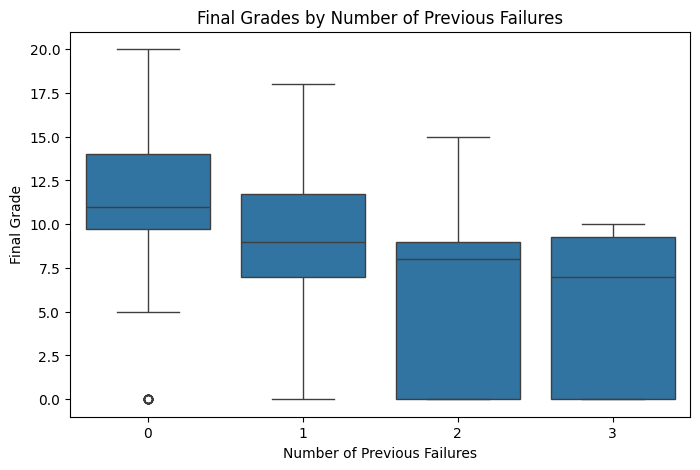

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='failures', y='G3')

plt.title('Final Grades by Number of Previous Failures')
plt.xlabel('Number of Previous Failures')
plt.ylabel('Final Grade')

plt.show()

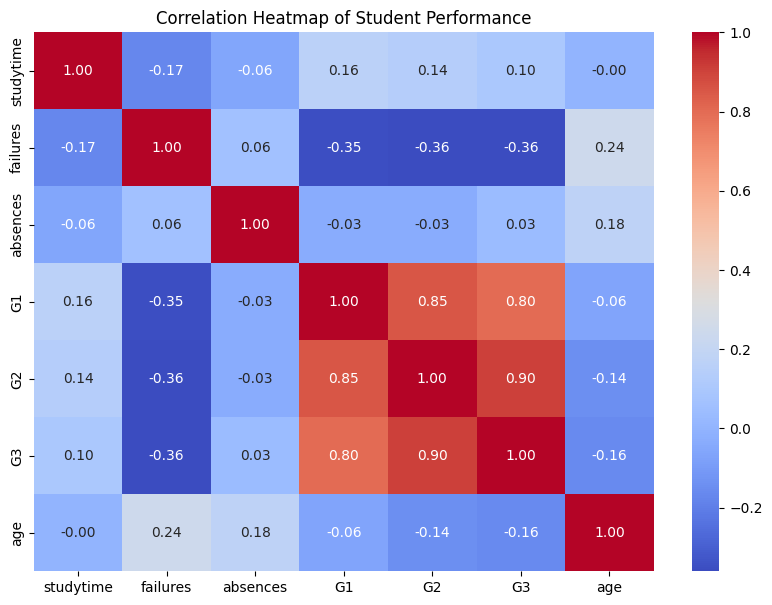

In [ ]:
plt.figure(figsize=(10,7))

correlation = df[
    ['studytime', 'failures', 'absences',
     'G1', 'G2', 'G3', 'age']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Student Performance')
plt.show()

In [ ]:
import os

os.makedirs('/content/visualizations',
exist_ok=True)

In [ ]:
plt.savefig('/content/visualizations/graph_name.png',
            dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
import os

os.makedirs('/content/visualizations', exist_ok=True)

print("Visualization folder created!")

Visualization folder created!


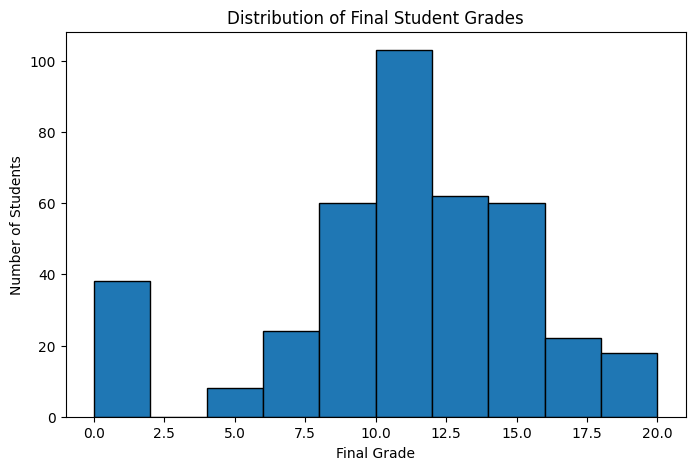

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['G3'], bins=10, edgecolor='black')

plt.title('Distribution of Final Student Grades')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')

plt.savefig('/content/visualizations/histogram.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
plt.savefig('/content/visualizations/bar_chart.png',
            dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig('/content/visualizations/scatter_plot.png',
            dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig('/content/visualizations/box_plot.png',
            dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig('/content/visualizations/heatmap.png',
            dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [ ]:
import shutil

shutil.make_archive(
    '/content/Student_Project_Graphs',
    'zip',
    '/content/visualizations'
)

print("All graphs saved in one ZIP file!")

All graphs saved in one ZIP file!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


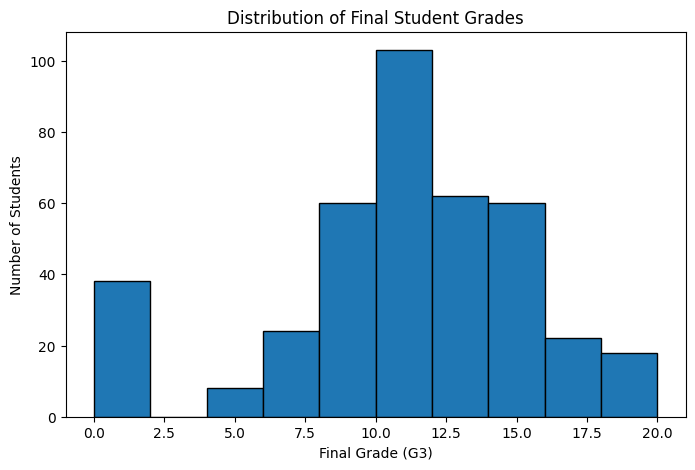

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['G3'], bins=10, edgecolor='black')
plt.title('Distribution of Final Student Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.savefig('/content/visualizations/histogram.png', dpi=300, bbox_inches='tight')
plt.show()

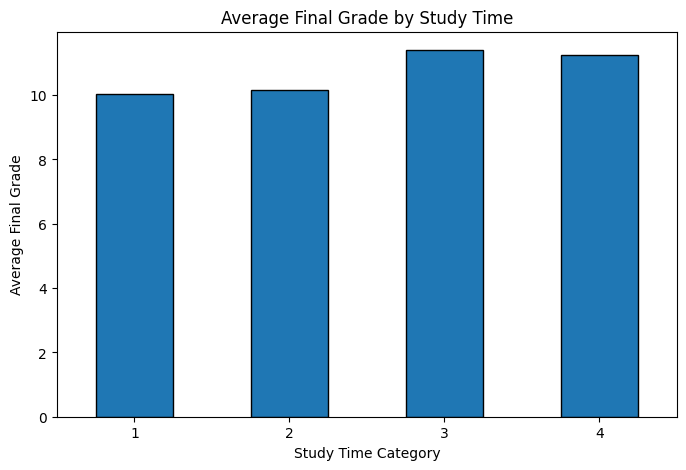

In [ ]:
plt.figure(figsize=(8,5))
study_performance = df.groupby('studytime')['G3'].mean()
study_performance.plot(kind='bar', edgecolor='black')
plt.title('Average Final Grade by Study Time')
plt.xlabel('Study Time Category')
plt.ylabel('Average Final Grade')
plt.xticks(rotation=0)
plt.savefig('/content/visualizations/bar_chart.png', dpi=300, bbox_inches='tight')
plt.show()

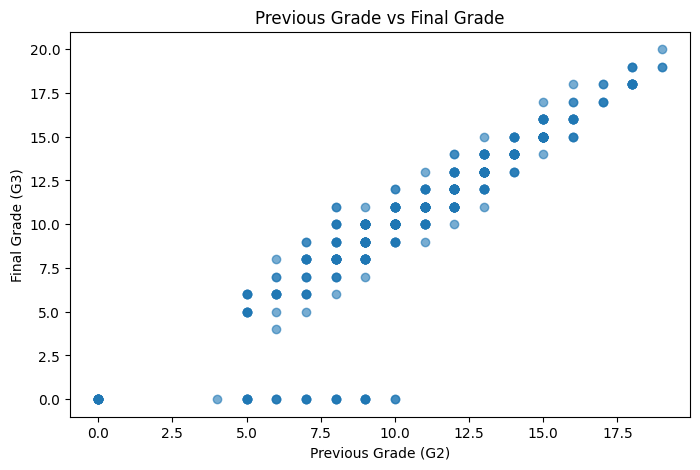

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['G2'], df['G3'], alpha=0.6)
plt.title('Previous Grade vs Final Grade')
plt.xlabel('Previous Grade (G2)')
plt.ylabel('Final Grade (G3)')
plt.savefig('/content/visualizations/scatter_plot.png', dpi=300, bbox_inches='tight')
plt.show()

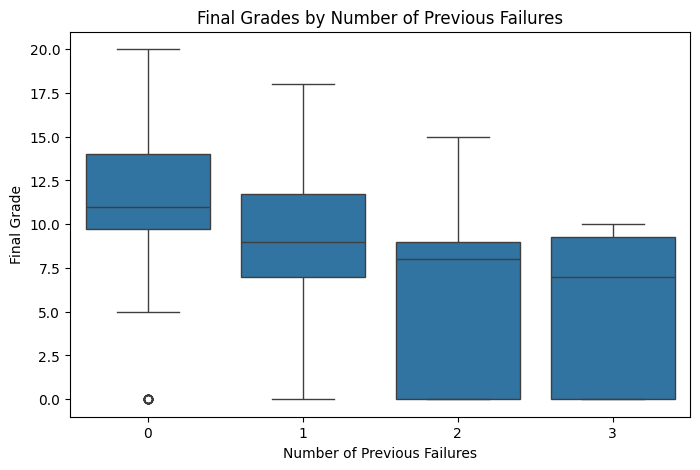

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='failures', y='G3')
plt.title('Final Grades by Number of Previous Failures')
plt.xlabel('Number of Previous Failures')
plt.ylabel('Final Grade')
plt.savefig('/content/visualizations/box_plot.png', dpi=300, bbox_inches='tight')
plt.show()

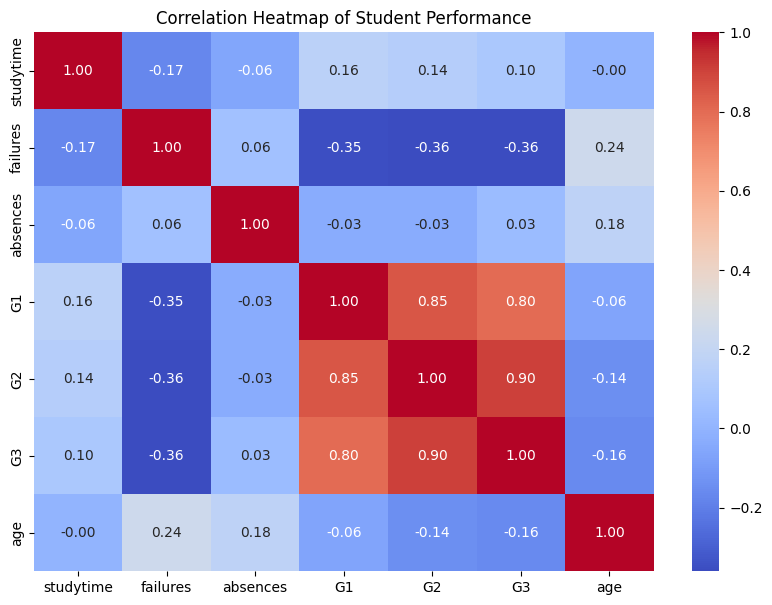

In [ ]:
plt.figure(figsize=(10,7))
correlation = df[['studytime','failures','absences','G1','G2','G3','age']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Student Performance')
plt.savefig('/content/visualizations/heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import shutil

shutil.make_archive(
    '/content/Student_Project_Graphs',
    'zip',
    '/content/visualizations'
)

print("All five graphs have been saved!")

All five graphs have been saved!


In [ ]:
import os

files = os.listdir('/content/visualizations')

for file in files:
    print(file)

scatter_plot.png
histogram.png
heatmap.png
box_plot.png
bar_chart.png
graph_name.png


In [ ]:
features = ['studytime', 'failures', 'absences', 'G1', 'G2', 'age']

X = df[features]
y = df['G3']

print("Features prepared successfully!")
print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

Features prepared successfully!
Input data shape: (395, 6)
Output data shape: (395,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and testing data created!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training and testing data created!
Training records: 316
Testing records: 79


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")

Machine Learning Model Trained Successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[ 6.11826915 11.96636043  3.20487573  8.60802677  7.43364276 12.41875419
 18.99059615  7.27464677  6.94764519 12.86857133]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

MODEL EVALUATION RESULTS
------------------------
MAE: 1.33
RMSE: 2.11
R² Score: 0.782


In [ ]:
results = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': np.round(y_pred, 2)
})

display(results.head(15))

,Actual Marks,Predicted Marks
0,10,6.12
1,12,11.97
2,5,3.20
3,10,8.61
4,9,7.43
5,13,12.42
6,18,18.99
7,6,7.27
8,0,6.95
9,14,12.87


In [ ]:
from sklearn.model_selection import cross_val_score, KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=kfold,
    scoring='r2'
)

print("CROSS-VALIDATION RESULTS")
print("------------------------")
print("Individual R2 scores:", cv_scores)
print("Average R2 score:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

parameters = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    ridge_pipeline,
    parameters,
    cv=5,
    scoring='r2'
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best alpha:", grid_search.best_params_)
print("Best cross-validation R2:", round(grid_search.best_score_, 3))

CROSS-VALIDATION RESULTS
------------------------
Individual R2 scores: [0.78239175 0.83075353 0.84304842 0.85599341 0.78062397]
Average R2 score: 0.819
Standard deviation: 0.031
Best alpha: {'ridge__alpha': 0.01}
Best cross-validation R2: 0.834


In [ ]:
ridge_predictions = best_model.predict(X_test)

print("Original Linear Regression R2:", round(r2, 3))
print("Tuned Ridge Regression R2:",
      round(r2_score(y_test, ridge_predictions), 3))

Original Linear Regression R2: 0.782
Tuned Ridge Regression R2: 0.782


In [ ]:
import joblib
import os

os.makedirs('/content/student_project', exist_ok=True)

joblib.dump(
    model,
    '/content/student_project/linear_regression_model.pkl'
)

joblib.dump(
    features,
    '/content/student_project/model_features.pkl'
)

print("Model and features saved successfully!")

Model and features saved successfully!


In [ ]:
df.to_csv(
    '/content/student_project/cleaned_student_data.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
import shutil

shutil.make_archive(
    '/content/Student_Performance_Project_Files',
    'zip',
    '/content/student_project'
)

print("Project ZIP created successfully!")

Project ZIP created successfully!


In [ ]:
import joblib

loaded_model = joblib.load(
    '/content/student_project/linear_regression_model.pkl'
)

loaded_features = joblib.load(
    '/content/student_project/model_features.pkl'
)

print("Model loaded successfully!")
print("Features:", loaded_features)

Model loaded successfully!
Features: ['studytime', 'failures', 'absences', 'G1', 'G2', 'age']


In [ ]:
import os

project_path = '/content/Student_Performance_Project'

folders = [
    'dataset',
    'visualizations',
    'model',
    'reports'
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import shutil
import os

# Copy cleaned dataset
shutil.copy2(
    '/content/student_project/cleaned_student_data.csv',
    '/content/Student_Performance_Project/dataset/'
)

# Copy trained model files
for file in os.listdir('/content/student_project'):
    if file.endswith('.pkl'):
        shutil.copy2(
            '/content/student_project/' + file,
            '/content/Student_Performance_Project/model/'
        )

# Copy all five graphs
for file in os.listdir('/content/visualizations'):
    if file.endswith('.png'):
        shutil.copy2(
            '/content/visualizations/' + file,
            '/content/Student_Performance_Project/visualizations/'
        )

print("All project files organised!")

All project files organised!


In [ ]:
for root, dirs, files in os.walk('/content/Student_Performance_Project'):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)


Folder: /content/Student_Performance_Project

Folder: /content/Student_Performance_Project/dataset
   cleaned_student_data.csv

Folder: /content/Student_Performance_Project/model
   linear_regression_model.pkl
   model_features.pkl

Folder: /content/Student_Performance_Project/reports

Folder: /content/Student_Performance_Project/visualizations
   scatter_plot.png
   histogram.png
   heatmap.png
   box_plot.png
   bar_chart.png
   graph_name.png


In [ ]:
import shutil
import os

folder_path = '/content/Student_Performance_Project'

zip_path = shutil.make_archive(
    '/content/Student_Performance_Project_Final',
    'zip',
    folder_path
    )

print("ZIP CREATED SUCCESSFULLY!")
print("File location:", zip_path)
print("File size:", os.path.getsize(zip_path), "bytes")

ZIP CREATED SUCCESSFULLY!
File location: /content/Student_Performance_Project_Final.zip
File size: 486686 bytes
